# Regression dự đoán chi tiêu khách hàng trong 90 ngày

Phần **Task 3 – Regression** được tách từ `Stage2_Final.ipynb` để chạy và làm báo cáo riêng.

**Mục tiêu:** dự đoán `Chi_tieu_90_ngay_GBP` từ 7 đặc trưng lịch sử. So sánh
`LinearRegression` và `DecisionTreeRegressor`, sử dụng 80% dữ liệu huấn luyện và 20% kiểm tra.

Chạy các ô từ trên xuống. Mở notebook trong thư mục đã giải nén có `data_regression.csv`.

## 1 Khai báo thư viện và các cột sử dụng

`CustomerID` chỉ dùng để đối chiếu khách hàng. Biến mục tiêu và các thông tin tương lai
không được đưa vào tập đặc trưng đầu vào.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
FEATURES = [
    "RecencyDays", "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "ObservedTenureDays", "AvgOrderValueGBP"
]
REG_TARGET = "Chi_tieu_90_ngay_GBP"

# File .py lấy đường dẫn theo vị trí của nó; notebook dùng thư mục đang mở.
PROJECT_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_PATH = PROJECT_DIR / "data_regression.csv"
OUTPUT_DIR = PROJECT_DIR / "ket_qua"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2 Đọc và kiểm tra dữ liệu

Tệp dữ liệu gồm 1.000 khách hàng, giữ nguyên giá trị và thứ tự từ dữ liệu Stage2.
Chỉ cần các cột dùng cho Regression; mỗi dòng là một khách hàng.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Không tìm thấy data_regression.csv. Hãy mở notebook trong thư mục Regression_Rieng."
    )

data = pd.read_csv(DATA_PATH)
required_columns = FEATURES + [REG_TARGET]
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Thiếu cột dữ liệu: {missing_columns}")

# Giữ cách xử lý của Stage2: loại dòng thiếu ở các cột cần sử dụng.
rows_before = len(data)
data = data.dropna(subset=required_columns).reset_index(drop=True)
print("Số khách hàng:", len(data))
print("Số dòng thiếu đã loại:", rows_before - len(data))
print("Số đặc trưng đầu vào:", len(FEATURES))
print(data.head().to_string(index=False))

Số khách hàng: 1000
Số dòng thiếu đã loại: 0
Số đặc trưng đầu vào: 7
 CustomerID  RecencyDays  Frequency  MonetaryGBP  TotalUnits  AvgProductsPerInvoice  ObservedTenureDays  AvgOrderValueGBP  Chi_tieu_90_ngay_GBP
      12354          132          1      1079.40         530              58.000000                 132       1079.400000                  0.00
      12358           50          3      1774.04         622              17.333333                 450        591.346667                  0.00
      12363            9          2       552.00         408              11.500000                 142        276.000000                  0.00
      12365          191          2       641.38         174              11.000000                 191        320.690000                  0.00
      12370          174          5      3018.07        2053              29.600000                 524        603.614000                739.28


## 3 Chia tập huấn luyện và tập kiểm tra

Tập huấn luyện chiếm 80%, tập kiểm tra chiếm 20%. Cả hai mô hình dùng cùng một lần
chia với `random_state=42` để có thể đối chiếu kết quả.

In [3]:
X_reg = data[FEATURES].copy()
y_reg = data[REG_TARGET].copy()

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Số khách hàng huấn luyện:", len(X_train_r))
print("Số khách hàng kiểm tra:", len(X_test_r))

Số khách hàng huấn luyện: 800
Số khách hàng kiểm tra: 200


## 4 Huấn luyện Linear Regression

Chuẩn hóa các đặc trưng bằng `StandardScaler`. Scaler chỉ học trung bình và độ lệch
chuẩn từ tập huấn luyện; tập kiểm tra dùng lại scaler này để tránh rò rỉ dữ liệu.

In [4]:
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

linear_model = LinearRegression()
linear_model.fit(X_train_r_scaled, y_train_r)
pred_linear = linear_model.predict(X_test_r_scaled)

print("Đã huấn luyện LinearRegression và dự đoán tập kiểm tra.")

Đã huấn luyện LinearRegression và dự đoán tập kiểm tra.


## 5 Huấn luyện Decision Tree Regressor

Cây quyết định dùng các đặc trưng gốc, với `max_depth=5` và `random_state=42`,
giữ nguyên thông số trong Stage2.

In [5]:
tree_reg_model = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)
tree_reg_model.fit(X_train_r, y_train_r)
pred_tree = tree_reg_model.predict(X_test_r)

print("Đã huấn luyện DecisionTreeRegressor và dự đoán tập kiểm tra.")

Đã huấn luyện DecisionTreeRegressor và dự đoán tập kiểm tra.


## 6 Đánh giá và so sánh hai mô hình

- **MSE:** trung bình bình phương sai số; càng thấp càng tốt, đơn vị GBP².
- **RMSE:** căn bậc hai của MSE; càng thấp càng tốt, đơn vị GBP.
- **R²:** hệ số xác định; giá trị cao hơn thể hiện kết quả tốt hơn trên cùng tập kiểm tra.
  R² không phải tỷ lệ dự đoán chính xác.

Mô hình được chọn theo R² cao nhất, sau đó ưu tiên RMSE thấp hơn nếu bằng nhau.
Đây là so sánh trên một lần chia dữ liệu cố định.

In [6]:
regression_rows = []
for name, actual, predicted in [
    ("LinearRegression", y_test_r, pred_linear),
    ("DecisionTreeRegressor", y_test_r, pred_tree),
]:
    mse = mean_squared_error(actual, predicted)
    regression_rows.append({
        "Model": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    })

regression_results = pd.DataFrame(regression_rows)
print(regression_results.round(4).to_string(index=False))
regression_winner = regression_results.sort_values(
    ["R2", "RMSE"], ascending=[False, True]
).iloc[0]["Model"]
print("Mô hình Regression được chọn:", regression_winner)

                Model         MSE     RMSE     R2
     LinearRegression 171854.2092 414.5530 0.3792
DecisionTreeRegressor 232378.6328 482.0567 0.1606
Mô hình Regression được chọn: LinearRegression


## 7 Vẽ biểu đồ thực tế và dự đoán

Biểu đồ dùng mô hình được chọn. Điểm càng gần đường nét đứt `dự đoán = thực tế`
thì sai số của khách hàng đó càng nhỏ. Giữ nguyên dự đoán thô để kết quả khớp Stage2.

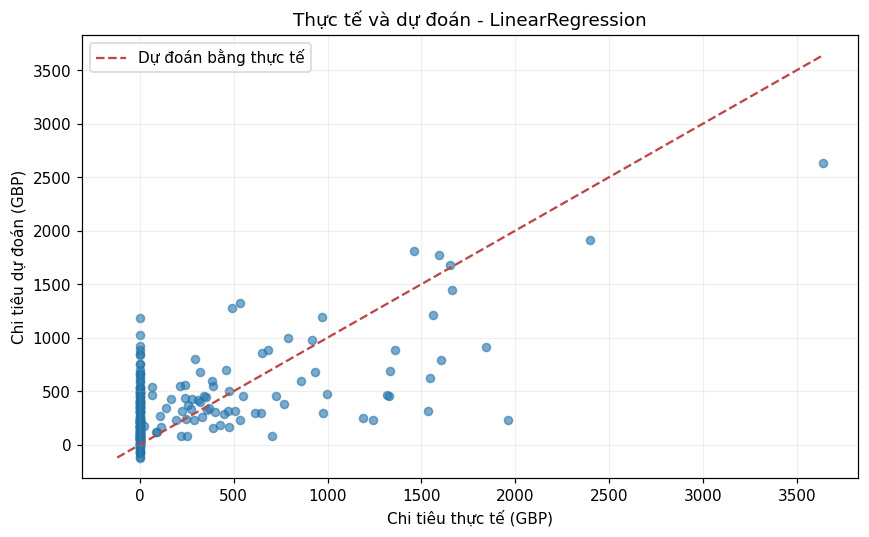

In [7]:
if regression_winner == "LinearRegression":
    best_reg_prediction = pred_linear
else:
    best_reg_prediction = pred_tree

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_test_r, best_reg_prediction, alpha=0.6, s=28, color="#2374AB")
minimum = min(float(y_test_r.min()), float(np.min(best_reg_prediction)))
maximum = max(float(y_test_r.max()), float(np.max(best_reg_prediction)))
ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="#BC4749",
        label="Dự đoán bằng thực tế")
ax.set_xlabel("Chi tiêu thực tế (GBP)")
ax.set_ylabel("Chi tiêu dự đoán (GBP)")
ax.set_title(f"Thực tế và dự đoán - {regression_winner}")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=200, bbox_inches="tight")
if "__file__" not in globals():
    plt.show()
plt.close(fig)

## 8 Xuất kết quả phục vụ báo cáo

Lưu bảng chỉ số, kết quả dự đoán của 200 khách hàng trong tập kiểm tra và ảnh biểu đồ
vào thư mục `ket_qua`. `CustomerID` chỉ được thêm vào kết quả để đối chiếu.

In [8]:
regression_results.to_csv(
    OUTPUT_DIR / "so_sanh_mo_hinh.csv", index=False, encoding="utf-8-sig"
)

test_predictions = pd.DataFrame({
    "Dong_du_lieu": X_test_r.index.to_numpy(),
    "Thuc_te_GBP": y_test_r.to_numpy(),
    "Du_doan_LinearRegression_GBP": pred_linear,
    "Du_doan_DecisionTree_GBP": pred_tree
})
if "CustomerID" in data.columns:
    test_predictions.insert(1, "CustomerID", data.loc[X_test_r.index, "CustomerID"].to_numpy())
test_predictions.to_csv(
    OUTPUT_DIR / "du_doan_tap_test.csv", index=False, encoding="utf-8-sig"
)

best_row = regression_results.loc[regression_results["Model"] == regression_winner].iloc[0]
print(f"Kết luận: {regression_winner} đạt R² = {best_row['R2']:.4f}, "
      f"RMSE = {best_row['RMSE']:.2f} GBP trên {len(y_test_r)} khách hàng kiểm tra.")
print("Đã lưu bảng chỉ số, dự đoán và biểu đồ vào:", OUTPUT_DIR)

Kết luận: LinearRegression đạt R² = 0.3792, RMSE = 414.55 GBP trên 200 khách hàng kiểm tra.
Đã lưu bảng chỉ số, dự đoán và biểu đồ vào: /workspace/scratch/d207c57aa0e7/output/Regression_Rieng/ket_qua


## Gợi ý nhận xét trong báo cáo

Trình bày mục tiêu, dữ liệu, cách chia tập, cách huấn luyện, bảng chỉ số và biểu đồ.
Giải thích mô hình nào tốt hơn **trong lần đánh giá này**, đồng thời nêu sai số còn lại.
Nếu tiếp tục tinh chỉnh mô hình, nên dùng validation hoặc cross-validation trên tập huấn luyện
và dành tập kiểm tra riêng cho đánh giá cuối cùng.